# Lab 2: Зниження розмірності, кластеризація та класифікація текстових даних

**Датасет:** Cybersecurity Risk and Action Scenarios - https://www.kaggle.com/datasets/ziya07/cybersecurity-threat-detection 

**Мета:** познайомитися з PCA, t-SNE, K-Means та базовим workflow класифікації текстів у Scikit-learn.

**Автор:** ФБ-62мп Тарасенко Ангеліна

In [4]:
%pip install scikit-learn pandas matplotlib seaborn wordcloud

In [5]:
import time, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, silhouette_score, adjusted_rand_score,
                             normalized_mutual_info_score, homogeneity_score, completeness_score)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42

У цьому фрагменті коду імпортуються необхідні бібліотеки та інструменти для аналізу даних, обробки текстів, машинного навчання та візуалізації результатів. NumPy і Pandas використовуються для роботи з даними, Matplotlib і Seaborn — для побудови графіків. Із бібліотеки Scikit-learn імпортуються методи зменшення розмірності (PCA, t-SNE), кластеризації (K-Means), класифікації (Logistic Regression, LinearSVC, Naive Bayes), а також інструменти для підготовки даних, перетворення текстів у числові ознаки (TF-IDF) та оцінювання якості моделей. Додатково імпортується датасет 20 Newsgroups для роботи з текстами, вимикаються попередження, встановлюється стиль графіків whitegrid і фіксується значення `SEED = 42` для відтворюваності результатів.

## 1. Зниження розмірності та візуалізація

### 1.1 Завантаження та підготовка даних

У цьому фрагменті коду виконується завантаження та початковий аналіз датасету `telesurgery_cybersecurity_dataset.csv`. Спочатку задаються основні параметри: шлях до файлу (`DATA_PATH`), цільова колонка (`TARGET_COL`), яка надалі може визначатися автоматично, максимальна кількість класів для аналізу (`MAX_CLASSES = 5`) та обмеження кількості точок для візуалізації й оцінювання кластеризації (`VIZ_SAMPLE = 3000`). Далі за допомогою `pd.read_csv()` датасет зчитується у DataFrame. Після цього виводяться його розмір (кількість рядків і стовпців), перші п’ять записів для ознайомлення зі структурою даних, кількість стовпців кожного типу даних, а також п’ять стовпців із найбільшою кількістю пропущених значень. Це дозволяє отримати загальне уявлення про датасет і визначити, чи потрібна додаткова обробка даних перед навчанням моделей.

In [6]:
DATA_PATH = "telesurgery_cybersecurity_dataset.csv"
TARGET_COL = None 
MAX_CLASSES = 5 
VIZ_SAMPLE = 3000

raw = pd.read_csv(DATA_PATH)
print("Розмір:", raw.shape)
display(raw.head())
print(raw.dtypes.value_counts())
print("Пропуски (топ-5):"); print(raw.isna().sum().sort_values(ascending=False).head(5))

Розмір: (1000, 18)


,Robot Gesture ID,Gesture Type,"Gesture Coordinates (x, y, z)",Timestamp,Gesture Duration (sec),Robot Status,Message ID,Sender,Receiver,Encryption Algorithm Used,Encryption Status,Network Latency (ms),Data Transfer Rate (Mbps),Threat Type,Threat Severity,Response Time (sec),Response Action Taken,Threat Detected
0,10,Incision,"(1.48, 1.4, 0.02)",2025-02-14 16:32:27,4.37,Idle,22614,Operator,Robot,Two Fish,Encrypted,11,97,Man-in-the-Middle Attack,Low,4.63,Reset Encryption,1
1,8,Diagnosis,"(1.62, 1.81, 0.68)",2025-02-14 16:32:27,3.08,Idle,61556,Operator,Robot,Two Fish,Encrypted,9,88,DoS Attack,Low,3.94,Reset Encryption,1
2,9,Incision,"(0.67, 1.53, 0.06)",2025-02-14 16:32:27,1.11,Active,27848,Operator,Robot,Two Fish,Encrypted,7,26,No Threat,Low,0.00,NaN,0
3,1,Incision,"(1.63, 1.74, 1.92)",2025-02-14 16:32:27,2.72,Idle,60592,Operator,Robot,Two Fish,Encrypted,13,56,Data Breach,High,4.58,Reconnect Connection,1
4,4,Suturing,"(0.53, 0.87, 1.17)",2025-02-14 16:32:27,1.20,Idle,46712,Robot,Operator,Two Fish,Failed,5,41,Man-in-the-Middle Attack,Low,2.46,Isolate Data,1


str        11
int64       5
float64     2
Name: count, dtype: int64
Пропуски (топ-5):
Response Action Taken    283
Robot Gesture ID           0
Gesture Type               0
Response Time (sec)        0
Threat Severity            0
dtype: int64


У результаті початкового аналізу встановлено, що датасет містить 1000 записів і 18 ознак, які описують роботу роботизованої системи, параметри мережевого з’єднання та кіберзагрози. Серед них є тип жесту робота, його координати, тривалість виконання операції, стан робота, параметри шифрування, затримка мережі, тип і рівень небезпеки загрози, час реагування та виконані захисні дії. За типами даних набір містить 11 текстових, 5 цілочисельних і 2 числові ознаки з плаваючою комою. Аналіз пропущених значень показав, що лише стовпець `Response Action Taken` містить пропуски — 283 записи (28,3%), тоді як інші стовпці заповнені повністю. З перших п’яти записів видно, що пропущена захисна дія може відповідати ситуації, коли загрозу не виявлено (No Threat), тому такі значення не обов’язково є помилкою. Загалом датасет має достатньо структурований вигляд, проте перед застосуванням алгоритмів машинного навчання необхідно обробити текстові ознаки, координати та пропущені значення.

У цьому фрагменті коду виконується підготовка даних до машинного навчання. Спочатку автоматично визначається цільова колонка (`TARGET_COL`), за якою модель буде здійснювати класифікацію. Якщо відповідної назви серед заданих варіантів немає, обирається остання колонка датасету, тобто в нашому випадку `Threat Detected`. Далі видаляються записи з пропущеними значеннями цільової змінної, підраховується кількість об’єктів кожного класу, а якщо класів більше п’яти, залишаються лише найчисельніші. За допомогою `LabelEncoder` текстові мітки класів перетворюються на числові значення. Після цього з набору ознак видаляються неінформативні колонки, зокрема ті, що містять лише одне унікальне значення, дати або текстові дані з великою кількістю унікальних значень. Пропущені значення в числових ознаках замінюються медіаною, а в категоріальних — значенням unknown. Категоріальні ознаки перетворюються на числові за допомогою `One-Hot Encoding`, після чого формується матриця ознак `X` та вектор цільових значень y. Наприкінці виводиться інформація про відкинуті колонки, кількість числових і категоріальних ознак, загальну кількість ознак після кодування та розподіл об’єктів за класами.

In [7]:
if TARGET_COL is None:
    prefer = ["label", "class", "target", "attack_type", "attack", "is_attack", "attack_label", "category", "y"]
    low = {c.lower(): c for c in raw.columns}
    TARGET_COL = next((low[p] for p in prefer if p in low), raw.columns[-1])
print("Цільова колонка:", TARGET_COL)

df0 = raw.dropna(subset=[TARGET_COL]).copy()
vc = df0[TARGET_COL].value_counts()
print(vc)
if len(vc) > MAX_CLASSES:
    keep = vc.index[:MAX_CLASSES]
    df0 = df0[df0[TARGET_COL].isin(keep)]
    print(f"Класів було {len(vc)}, залишено {MAX_CLASSES} найчисельніших: {list(keep)}")

le = LabelEncoder()
y = le.fit_transform(df0[TARGET_COL].astype(str))
class_names = list(le.classes_)
feat = df0.drop(columns=[TARGET_COL])

drop_cols = []
for c in feat.columns:
    s = feat[c]
    if s.nunique(dropna=True) <= 1:          
        drop_cols.append(c)
    elif s.dtype == object or pd.api.types.is_string_dtype(s) or str(s.dtype) in ("category", "str"):
        parsed = pd.to_datetime(s, errors="coerce")
        if parsed.notna().mean() > 0.9:               
            drop_cols.append(c)
        elif s.nunique() > 30:            
            drop_cols.append(c)
    elif "id" == c.lower() or c.lower().endswith("_id"):
        drop_cols.append(c)
print("Відкинуті колонки:", drop_cols)
feat = feat.drop(columns=drop_cols)

num_cols = feat.select_dtypes(include=[np.number, bool]).columns.tolist()
cat_cols = [c for c in feat.columns if c not in num_cols]
feat[num_cols] = feat[num_cols].astype(float).fillna(feat[num_cols].astype(float).median())
feat[cat_cols] = feat[cat_cols].fillna("unknown")
X_df = pd.get_dummies(feat, columns=cat_cols, drop_first=False, dtype=float)
X = X_df.values
feature_names = X_df.columns.tolist()
print(f"Числових: {len(num_cols)}, категоріальних: {len(cat_cols)} -> всього ознак після кодування: {X.shape[1]}")
print("Класи:", dict(zip(class_names, np.bincount(y))))

Цільова колонка: Threat Detected
Threat Detected
1    717
0    283
Name: count, dtype: int64
Відкинуті колонки: ['Gesture Coordinates (x, y, z)', 'Timestamp', 'Encryption Algorithm Used']
Числових: 6, категоріальних: 8 -> всього ознак після кодування: 30
Класи: {'0': np.int32(283), '1': np.int32(717)}


У результаті попередньої обробки даних цільовою колонкою було визначено `Threat Detected`, яка показує, чи була виявлена кіберзагроза. Датасет містить два класи: 1 — загрозу виявлено (717 записів, 71,7%) та 0 — загрозу не виявлено (283 записи, 28,3%). Такий розподіл свідчить про певний дисбаланс класів, оскільки випадків виявлення загроз значно більше. Під час підготовки даних було видалено три колонки: `Gesture Coordinates` (x, y, z), `Timestamp` та `Encryption Algorithm Used`, оскільки вони відповідали критеріям автоматичного відбору неінформативних або складних для обробки ознак. Після цього залишилося 6 числових і 8 категоріальних ознак, які після застосування `One-Hot Encoding` були перетворені на 30 числових ознак. Таким чином, дані підготовлено для подальшого використання алгоритмів класифікації та кластеризації. При цьому під час оцінювання моделей важливо враховувати дисбаланс класів, використовуючи не лише `Accuracy`, а й `Precision`, `Recall` та `F1-score`.

У цьому фрагменті коду виконується розділення датасету на навчальну та тестову вибірки, а також стандартизація ознак для подальшого навчання моделей. За допомогою `train_test_split()` дані поділяються у співвідношенні 75% для навчання (750 записів) та 25% для тестування (250 записів). Параметр `stratify=y` забезпечує збереження приблизно однакового співвідношення класів в обох вибірках, що особливо важливо за наявності дисбалансу класів. Параметр `random_state=SEED` забезпечує відтворюваність результатів. Далі за допомогою `StandardScaler` виконується стандартизація ознак, тобто приведення їх до масштабу із середнім значенням 0 та стандартним відхиленням 1 на навчальній вибірці. При цьому параметри масштабування обчислюються лише на навчальних даних, щоб уникнути витоку інформації з тестової вибірки. Наприкінці виводяться розміри отриманих масивів, які використовуватимуться для навчання та оцінювання моделей машинного навчання.

In [8]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
scaler = StandardScaler().fit(X_tr)
X_tr_s, X_te_s = scaler.transform(X_tr), scaler.transform(X_te)
print("train:", X_tr_s.shape, "test:", X_te_s.shape)

train: (750, 30) test: (250, 30)


У результаті розділення датасету отримано 750 записів для навчання та 250 для тестування моделі. Кожен запис містить 30 числових ознак після попередньої обробки та кодування. Дані стандартизовано й підготовлено для подальшого навчання та оцінювання моделей.

### 1.2 Класифікація «до» PCA (базова модель — логістична регресія)

У цьому фрагменті коду створюється функція `fit_eval()`, яка використовується для навчання та оцінювання моделі логістичної регресії (`Logistic Regression`). Модель навчається на тренувальних даних п’ять разів, при цьому для кожного запуску вимірюється час навчання, після чого обчислюється його середнє значення. Далі остання навчена модель виконує прогнозування на тестовій вибірці, а її якість оцінюється за метриками `Accuracy` (частка правильних прогнозів) та `F1-macro` (середнє значення `F1-score` для всіх класів без урахування їхньої чисельності). Функція повертає кількість використаних ознак, точність класифікації, F1-macro та середній час навчання. Наприкінці отримані результати зберігаються у змінній `base`, яка слугує базовим показником для подальшого порівняння моделей.

In [9]:
def fit_eval(Xa, Xb, n_rep=5):
    times = []
    for _ in range(n_rep):
        clf = LogisticRegression(max_iter=3000, random_state=SEED)
        t = time.perf_counter(); clf.fit(Xa, y_tr); times.append(time.perf_counter() - t)
    pred = clf.predict(Xb)
    return dict(n_features=Xa.shape[1], accuracy=accuracy_score(y_te, pred),
                f1_macro=f1_score(y_te, pred, average="macro"), fit_time_s=float(np.mean(times)))

base = fit_eval(X_tr_s, X_te_s)
base

{'n_features': 30,
 'accuracy': 1.0,
 'f1_macro': 1.0,
 'fit_time_s': 0.009139999999933934}

У результаті навчання модель логістичної регресії показала ідеальні результати класифікації: `Accuracy = 1.0 (100%)` та `F1-macro = 1.0`, тобто всі 250 тестових записів були класифіковані правильно. Модель використовувала 30 ознак, а середній час навчання становив лише 0,0091 секунди. Проте такі високі показники можуть свідчити про витік інформації через ознаки, безпосередньо пов’язані з цільовою змінною, тому результати потребують додаткової перевірки.

### 1.3 PCA: вибір кількості компонент та порівняння

У цьому фрагменті коду застосовується метод головних компонент (PCA) для аналізу можливості зменшення розмірності даних зі збереженням максимальної кількості інформації. Спочатку PCA навчається на стандартизованій тренувальній вибірці, після чого обчислюється накопичена частка поясненої дисперсії для кожної кількості компонент. Далі визначається мінімальна кількість головних компонент (n95), необхідна для збереження 95% загальної дисперсії даних. На основі отриманих значень будується графік, який показує залежність накопиченої поясненої дисперсії від кількості компонент. Червона пунктирна лінія позначає поріг 95%, а зелена - кількість компонент, необхідних для його досягнення. Це дозволяє визначити, наскільки можна скоротити кількість ознак без суттєвої втрати інформації про мінливість даних.

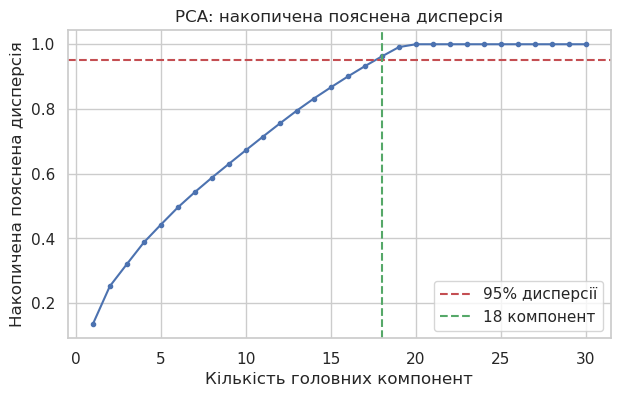

In [10]:
pca_full = PCA(random_state=SEED).fit(X_tr_s)
cum = np.cumsum(pca_full.explained_variance_ratio_)
n95 = int(np.argmax(cum >= 0.95)) + 1

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cum) + 1), cum, marker=".")
plt.axhline(0.95, color="r", ls="--", label="95% дисперсії")
plt.axvline(n95, color="g", ls="--", label=f"{n95} компонент")
plt.xlabel("Кількість головних компонент"); plt.ylabel("Накопичена пояснена дисперсія")
plt.legend(); plt.title("PCA: накопичена пояснена дисперсія"); plt.show()

За результатами PCA встановлено, що для збереження 95% загальної дисперсії даних достатньо 18 головних компонент із початкових 30 ознак. Це дозволяє скоротити розмірність даних на 40%, зберігши більшу частину інформації про їхню мінливість. На графіку видно, що зі збільшенням кількості компонент накопичена пояснена дисперсія поступово зростає, а приблизно після 20 компонент досягає 100%. Таким чином, використання PCA дозволяє зменшити кількість ознак, потенційно скоротити обчислювальні витрати та спростити подальший аналіз даних. Водночас збереження 95% дисперсії не гарантує збереження такої самої точності класифікації, тому це необхідно перевірити експериментально.

У цьому фрагменті коду виконується зменшення розмірності даних за допомогою PCA та порівняння результатів класифікації до і після його застосування. Спочатку PCA налаштовується так, щоб зберегти 95% поясненої дисперсії, після чого навчальна та тестова вибірки перетворюються з початкових 30 ознак на 18 головних компонент. Далі за допомогою функції `fit_eval()` повторно навчається та оцінюється модель логістичної регресії на зменшеному наборі ознак. Отримані результати порівнюються з початковою моделлю за кількістю ознак, точністю класифікації (`Accuracy`), F1-macro та середнім часом навчання. Результати виводяться у вигляді таблиці, а також обчислюється відсоток скорочення кількості ознак, зміна метрик якості та часу навчання. Це дозволяє оцінити, чи допомагає PCA зменшити обчислювальні витрати без суттєвого погіршення якості класифікації.

In [11]:
pca = PCA(n_components=0.95, random_state=SEED).fit(X_tr_s)
X_tr_p, X_te_p = pca.transform(X_tr_s), pca.transform(X_te_s)
res_pca = fit_eval(X_tr_p, X_te_p)

comparison = pd.DataFrame([dict(model="До PCA", **base), dict(model="Після PCA (95% дисперсії)", **res_pca)])
display(comparison.round(4))
n0, n1 = X_tr_s.shape[1], pca.n_components_
print(f"Ознак: {n0} -> {n1}  (зменшення у {n0/n1:.2f} раза, -{(1 - n1/n0)*100:.0f}%)")
print(f"Зміна accuracy: {res_pca['accuracy'] - base['accuracy']:+.4f} | зміна F1-macro: {res_pca['f1_macro'] - base['f1_macro']:+.4f}")
print(f"Час навчання: {base['fit_time_s']*1000:.1f} мс -> {res_pca['fit_time_s']*1000:.1f} мс")

,model,n_features,accuracy,f1_macro,fit_time_s
0,До PCA,30,1.0,1.0,0.0091
1,Після PCA (95% дисперсії),18,1.0,1.0,0.0048


Ознак: 30 -> 18  (зменшення у 1.67 раза, -40%)
Зміна accuracy: +0.0000 | зміна F1-macro: +0.0000
Час навчання: 9.1 мс -> 4.8 мс


За результатами порівняння встановлено, що застосування PCA дозволило зменшити кількість ознак із 30 до 18 (на 40%), при цьому якість класифікації залишилася незмінною. Як до, так і після PCA модель логістичної регресії досягла `Accuracy = 1.0` та `F1-macro = 1.0`, тобто правильно класифікувала всі тестові записи. Водночас середній час навчання скоротився з 9,1 мс до 4,8 мс, що майже вдвічі швидше. Таким чином, PCA виявився ефективним для зменшення розмірності даних і прискорення навчання без втрати точності. Однак ідеальні результати класифікації можуть свідчити про витік інформації через окремі ознаки, тому перед остаточними висновками варто перевірити їхній зв'язок із цільовою змінною.

У цьому фрагменті коду досліджується вплив кількості головних компонент PCA на точність класифікації. Спочатку формується список різних значень кількості компонент (від 2 до 30), для кожного з яких виконується зменшення розмірності навчальної та тестової вибірок. Далі за допомогою функції `fit_eval()` навчається модель логістичної регресії та обчислюються її показники якості (`Accuracy`, `F1-macro`) і середній час навчання. Отримані результати зберігаються в таблиці `sweep`. Після цього будується графік залежності точності класифікації від кількості компонент PCA, де червона пунктирна лінія показує точність початкової моделі без PCA. Наприкінці виводиться таблиця з результатами для кожної кількості компонент. Це дозволяє визначити, яку мінімальну кількість компонент можна використати для збереження високої точності класифікації та оцінити вплив зменшення розмірності на швидкість навчання моделі.

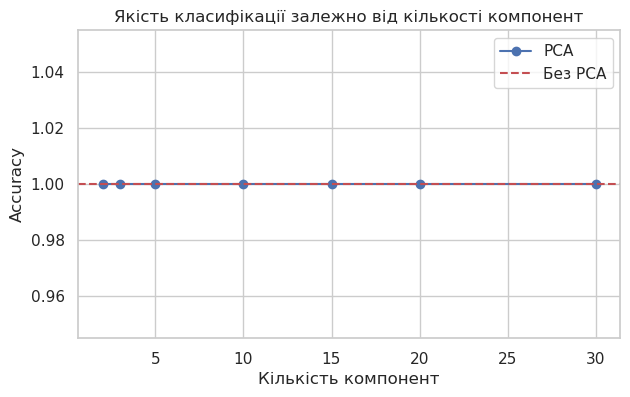

,n_features,accuracy,f1_macro,fit_time_s
0,2,1.0,1.0,0.0062
1,3,1.0,1.0,0.0045
2,5,1.0,1.0,0.0041
3,10,1.0,1.0,0.0040
4,15,1.0,1.0,0.0044
5,20,1.0,1.0,0.0048
6,30,1.0,1.0,0.0052


In [12]:
max_k = X_tr_s.shape[1]
grid = sorted({k for k in [2, 3, 5, 10, 15, 20, 30, 40, max_k] if k <= min(max_k, X_tr_s.shape[0])})
rows = []
for k in grid:
    p = PCA(n_components=k, random_state=SEED).fit(X_tr_s)
    rows.append(fit_eval(p.transform(X_tr_s), p.transform(X_te_s), n_rep=3))
sweep = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sweep.n_features, sweep.accuracy, marker="o", label="PCA")
ax.axhline(base["accuracy"], color="r", ls="--", label="Без PCA")
ax.set_xlabel("Кількість компонент"); ax.set_ylabel("Accuracy"); ax.legend()
ax.set_title("Якість класифікації залежно від кількості компонент"); plt.show()
display(sweep.round(4))

За результатами експерименту встановлено, що точність класифікації залишається незмінною (`Accuracy = 1.0` та `F1-macro = 1.0`) незалежно від кількості головних компонент PCA. Навіть використання лише 2 компонент замість початкових 30 забезпечило 100% правильних прогнозів на тестовій вибірці. Це свідчить про те, що для класифікації достатньо значно меншої кількості ознак. Найменший середній час навчання спостерігався при використанні 10 компонент (0,0040 с), тоді як для 2 компонент він становив 0,0062 с, а для 30 - 0,0052 с. Таким чином, зменшення розмірності за допомогою PCA дозволяє зберегти якість класифікації та скоротити обчислювальні витрати. Водночас ідеальна точність навіть із двома компонентами може свідчити про наявність витоку інформації через ознаки, тісно пов'язані з цільовою змінною, тому отримані результати потребують додаткової перевірки.

### 1.4 Висновки щодо PCA
Числа для висновків виводяться клітинками вище. Як їх інтерпретувати:
* **Кількість ознак** - після застосування PCA кількість ознак зменшилася з 30 до 18 (на 40%) зі збереженням 95% поясненої дисперсії. Це свідчить про можливість суттєвого стиснення даних без значної втрати інформації.
* **Якість** - показники `Accuracy` та `F1-macro` залишилися незмінними (1.0) як до, так і після PCA. Графік показав, що навіть за використання лише 2 компонент точність класифікації становить 100%, тобто якість виходить на плато вже при мінімальній кількості компонент. Водночас такі результати потребують перевірки на можливий витік інформації.
* **Час навчання** - після PCA середній час навчання скоротився з 9,1 мс до 4,8 мс (приблизно на 47%). Найменший час (4,0 мс) спостерігався при використанні 10 компонент, однак на такому невеликому датасеті різниця може частково пояснюватися похибкою вимірювання.

**Висновки:** PCA дозволив зменшити розмірність даних на 40% без втрати точності класифікації. При цьому час навчання скоротився майже вдвічі, що демонструє потенційну ефективність методу для оптимізації моделі.

### 1.5 t-SNE: проєкція у 2D


У цьому фрагменті коду виконується зменшення розмірності даних та порівняння методів PCA і t-SNE для двовимірної візуалізації класів. Спочатку всі ознаки стандартизуються за допомогою `StandardScaler`, після чого випадковим чином відбирається до 3000 записів для візуалізації (у нашому випадку всі 1000 записів). Далі застосовується метод t-SNE, який перетворює багатовимірні дані у двовимірний простір, намагаючись зберегти локальну схожість між об'єктами. Для порівняння використовується PCA з двома головними компонентами, який зберігає напрями найбільшої дисперсії даних. Також вимірюється час виконання t-SNE. Наприкінці будуються два графіки розсіювання: ліворуч - результат PCA, праворуч - t-SNE, де точки позначають окремі записи датасету, а кольори відповідають класам (0 - загрозу не виявлено, 1 - загрозу виявлено). Це дозволяє візуально порівняти, наскільки добре обидва методи відображають структуру даних і розділення класів у двовимірному просторі.

Точок для візуалізації: 1000
t-SNE: 12.9 с


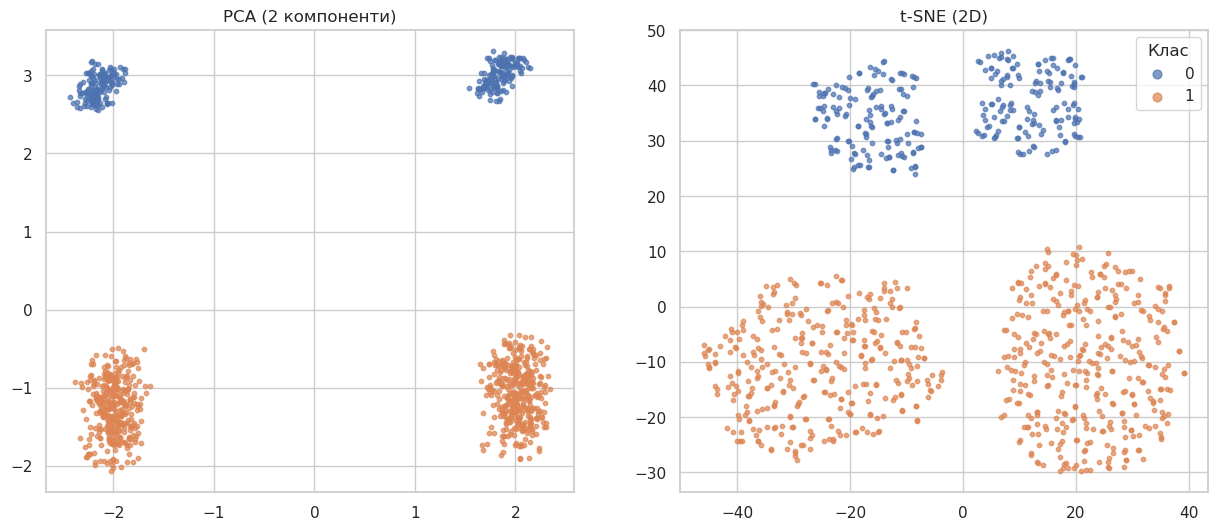

In [14]:
X_all_s = StandardScaler().fit_transform(X) 
rng = np.random.RandomState(SEED)
idx = rng.choice(len(X_all_s), size=min(VIZ_SAMPLE, len(X_all_s)), replace=False)
Xv, yv = X_all_s[idx], y[idx]             
print("Точок для візуалізації:", len(idx))

t0 = time.perf_counter()
X_tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(Xv)
print(f"t-SNE: {time.perf_counter() - t0:.1f} с")
X_pca2 = PCA(n_components=2, random_state=SEED).fit_transform(Xv)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, emb, name in zip(axes, [X_pca2, X_tsne], ["PCA (2 компоненти)", "t-SNE (2D)"]):
    for c, cname in enumerate(class_names):
        m = yv == c; ax.scatter(emb[m, 0], emb[m, 1], s=10, label=cname, alpha=0.7)
    ax.set_title(name)
axes[1].legend(title="Клас", markerscale=2, loc="best")
plt.show()

У результаті застосування методів PCA та t-SNE було отримано двовимірні візуалізації 1000 записів датасету. Обидва методи продемонстрували чітке розділення двох класів: 0 - загрозу не виявлено (сині точки) та 1 — загрозу виявлено (помаранчеві точки). На графіку PCA видно чотири компактні групи, при цьому об'єкти різних класів не перетинаються. Метод t-SNE також добре розділив класи, однак сформував більш розподілені групи, що дозволяє детальніше розглянути локальну структуру даних. Час виконання t-SNE становив 12,9 секунди, що свідчить про його більшу обчислювальну складність порівняно з PCA. Таким чином, обидва методи успішно відобразили відмінності між класами, але PCA забезпечив більш компактне та наочне представлення даних, тоді як t-SNE дозволив краще розглянути внутрішній розподіл об'єктів. Водночас настільки чітке розділення класів може бути пов'язане з наявністю ознак, які безпосередньо вказують на факт виявлення загрози.

## 2. Кластерний аналіз (K-Means)

Мітки `y` **не використовуються** під час кластеризації — лише для порівняння наприкінці.

### 2.1 Вибір кількості кластерів: Elbow та Silhouette

У цьому фрагменті коду виконується визначення оптимальної кількості кластерів для алгоритму `K-Means` за допомогою методів `Elbow` (метод ліктя) та `Silhouette Score` (коефіцієнт силуету). Спочатку алгоритм `K-Means` послідовно застосовується до стандартизованих даних із кількістю кластерів від 2 до 10. Для кожного значення k обчислюється `Inertia` (WCSS) - сума квадратів відстаней об'єктів до центрів своїх кластерів, а також `Silhouette Score`, який оцінює компактність кластерів та їхню відокремленість один від одного. Далі будуються два графіки: перший дозволяє знайти точку, після якої зменшення `Inertia` сповільнюється, а другий показує, за якої кількості кластерів досягається найвище значення `Silhouette Score`. Наприкінці виводиться таблиця результатів, визначається оптимальне k за максимальним `Silhouette Score` та порівнюється з реальною кількістю класів у датасеті (2). Це дозволяє оцінити, наскільки природна структура даних відповідає відомому поділу на класи.

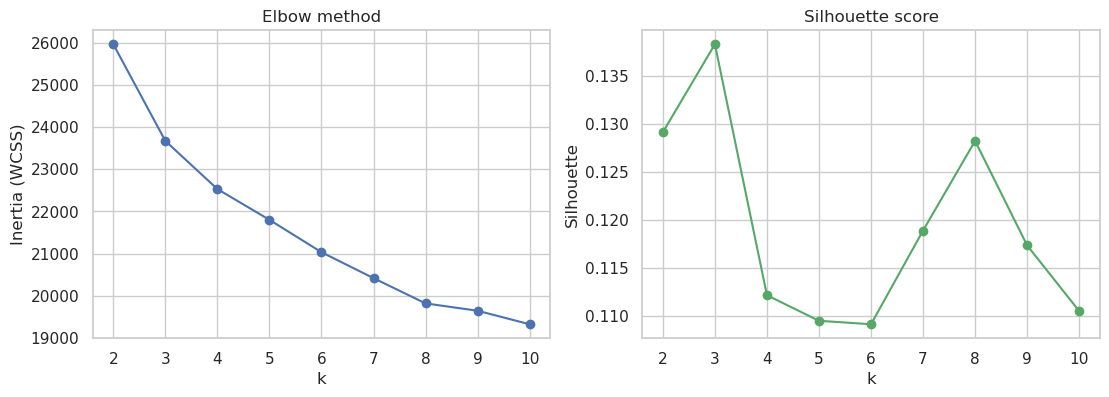

 k  inertia  silhouette
 2  25975.0       0.129
 3  23677.0       0.138
 4  22533.0       0.112
 5  21802.0       0.110
 6  21032.0       0.109
 7  20416.0       0.119
 8  19816.0       0.128
 9  19640.0       0.117
10  19320.0       0.111
k з максимальним silhouette: 3 | кількість справжніх класів: 2


In [15]:
ks = list(range(2, 11))
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_all_s)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_all_s, km.labels_, sample_size=min(5000, len(X_all_s)), random_state=SEED))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(ks, inertia, marker="o"); axes[0].set_title("Elbow method"); axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia (WCSS)")
axes[1].plot(ks, sil, marker="o", color="g"); axes[1].set_title("Silhouette score"); axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette")
plt.show()
print(pd.DataFrame({"k": ks, "inertia": np.round(inertia, 0), "silhouette": np.round(sil, 3)}).to_string(index=False))
best_k_sil = ks[int(np.argmax(sil))]
print("k з максимальним silhouette:", best_k_sil, "| кількість справжніх класів:", len(class_names))

За результатами дослідження алгоритму K-Means було встановлено, що зі збільшенням кількості кластерів від 2 до 10 значення Inertia поступово зменшується з 25975 до 19320, що свідчить про зменшення відстаней між об'єктами та центрами їхніх кластерів. На графіку `Elbow method` найбільш помітне зниження `Inertia` спостерігається при переході від 2 до 3 кластерів, після чого покращення поступово сповільнюється, хоча чітко вираженої точки ліктя немає. Найвище значення `Silhouette Score` (0,138) отримано при `k = 3`, тому за цим критерієм оптимальною є кількість у 3 кластери. Водночас у датасеті існує лише 2 справжні класи, отже, структура кластерів не повністю відповідає початковому поділу даних. Крім того, низькі значення `Silhouette Score` для всіх перевірених варіантів (0,109–0,138) свідчать про слабку відокремленість кластерів у багатовимірному просторі. Таким чином, K-Means виявив певну внутрішню структуру даних, проте якість кластеризації залишається невисокою.

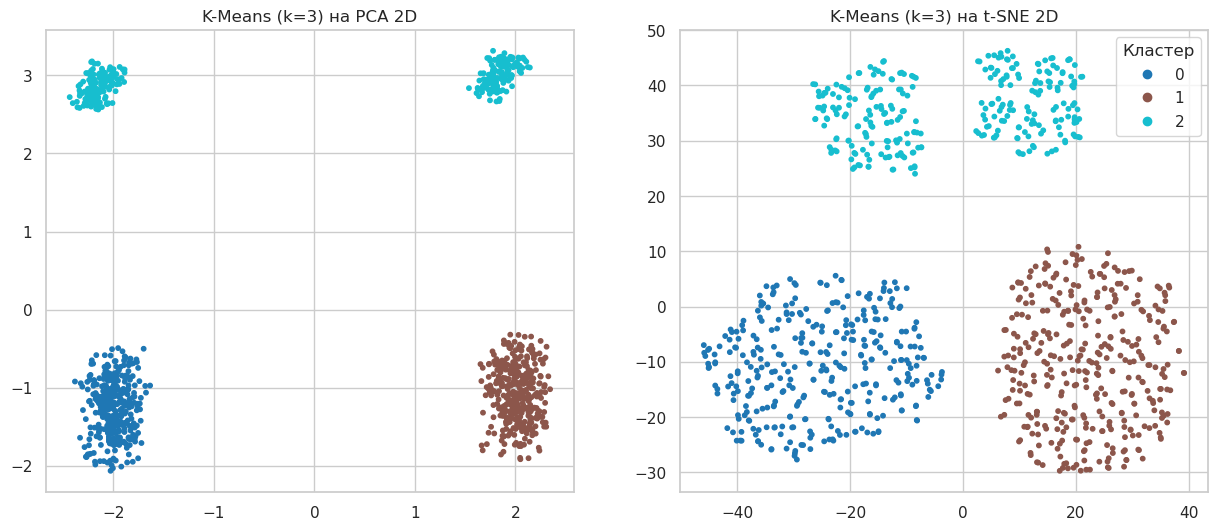

In [16]:
K = best_k_sil      
km = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X_all_s)
labels = km.labels_
lab_v = labels[idx]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, emb, name in zip(axes, [X_pca2, X_tsne], ["PCA 2D", "t-SNE 2D"]):
    sc = ax.scatter(emb[:, 0], emb[:, 1], c=lab_v, cmap="tab10", s=10)
    ax.set_title(f"K-Means (k={K}) на {name}")
axes[1].legend(*sc.legend_elements(), title="Кластер", loc="best")
plt.show()

За результатами візуалізації кластеризації `K-Means` із кількістю кластерів k = 3 видно, що алгоритм розділив дані на три групи, які чітко відображаються як на графіку PCA, так і на графіку t-SNE. На графіку PCA спостерігаються чотири просторово відокремлені групи точок, проте дві верхні групи об'єднані в один кластер (бірюзовий), тоді як дві нижні віднесені до різних кластерів (синього та коричневого). На графіку t-SNE спостерігається аналогічний розподіл, але групи мають більш розсіяну форму, що дозволяє краще розглянути їхню внутрішню структуру. Верхній кластер відповідає об'єктам без виявлених загроз, а два нижні - об'єктам із виявленими загрозами, тобто алгоритм додатково розділив один зі справжніх класів на дві групи. Таким чином, K-Means виявив структуру даних, яка частково відповідає реальним класам, але має додатковий поділ. Водночас попередньо отриманий низький `Silhouette Score` (0,138) свідчить, що попри візуально чітке розділення у двовимірному просторі, загальна якість кластеризації у вихідному багатовимірному просторі залишається невисокою.

### 2.2 Порівняння кластерів зі справжніми класами

У цьому фрагменті коду виконується оцінювання якості кластеризації `K-Means` та порівняння отриманих кластерів зі справжніми класами датасету. Спочатку створюється функція `cluster_report()`, яка обчислює чотири метрики: ARI (ступінь відповідності кластерів справжнім класам з урахуванням випадкових збігів), NMI (нормалізована взаємна інформація між класами та кластерами), Homogeneity (наскільки кожен кластер містить об'єкти одного класу) та Completeness (наскільки всі об'єкти одного класу потрапляють до одного кластера). Далі результати виводяться у вигляді таблиці, а за допомогою теплової карти (heatmap) візуалізується розподіл справжніх класів між отриманими кластерами. Після цього проводиться аналіз чутливості до кількості кластерів: `K-Means` повторно запускається для кількох значень k, зокрема 2, 3 та 5, і для кожного обчислюються ті самі метрики. Це дозволяє визначити, наскільки добре результати кластеризації відповідають реальним класам і як зміна кількості кластерів впливає на якість групування даних.


,ARI,NMI,homogeneity,completeness
k=3,0.515,0.706,1.0,0.545


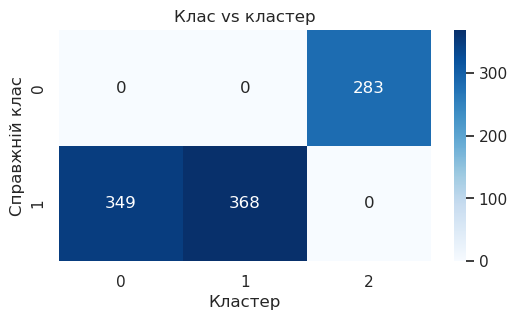

,k,ARI,NMI,homogeneity,completeness
0,2,-0.000,0.000,0.0,0.000
1,3,0.515,0.706,1.0,0.545
2,5,0.348,0.560,1.0,0.389


In [17]:
def cluster_report(y_true, lab):
    return dict(ARI=adjusted_rand_score(y_true, lab), NMI=normalized_mutual_info_score(y_true, lab),
                homogeneity=homogeneity_score(y_true, lab), completeness=completeness_score(y_true, lab))

display(pd.DataFrame([cluster_report(y, labels)], index=[f"k={K}"]).round(3))

ct = pd.crosstab(pd.Series([class_names[i] for i in y], name="Справжній клас"), pd.Series(labels, name="Кластер"))
plt.figure(figsize=(max(6, K), max(3, len(class_names)))); sns.heatmap(ct, annot=True, fmt="d", cmap="Blues")
plt.title("Клас vs кластер"); plt.show()

rows = []
for k in sorted({2, len(class_names), K, K + 2}):
    l = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X_all_s)
    rows.append(dict(k=k, **cluster_report(y, l)))
display(pd.DataFrame(rows).round(3))

За результатами оцінювання кластеризації `K-Means` найкращі показники отримано при `k = 3`: `ARI = 0,515`, `NMI = 0,706`, `Homogeneity = 1,0` та `Completeness = 0,545`. Значення ARI свідчить про помірну відповідність отриманих кластерів справжнім класам, а NMI — про досить сильний зв'язок між ними. `Homogeneity = 1,0` означає, що кожен кластер містить об'єкти лише одного класу, проте невисоке значення Completeness показує, що об'єкти одного класу розподілені між кількома кластерами. Це підтверджується тепловою картою: усі 283 записи класу 0 потрапили до кластера 2, тоді як 717 записів класу 1 розділилися між кластерами 0 (349 записів) та 1 (368 записів). Аналіз чутливості показав, що при k = 2 кластеризація практично не відповідає справжнім класам (`ARI ≈ 0`, `NMI = 0`), а при k = 5 якість погіршується порівняно з `k = 3` (`ARI = 0,348`, `NMI = 0,560`). Таким чином, оптимальним серед перевірених варіантів є `k = 3`, оскільки алгоритм правильно відокремлює об'єкти різних класів, хоча й додатково розділяє один із них на дві групи.

### 2.3 Висновок щодо кластерів
За результатами кластеризації K-Means найкращі показники отримано при `k = 3`: `ARI = 0,515`, `NMI = 0,706`, `Homogeneity = 1,0` та `Completeness = 0,545`. Це свідчить про помірну відповідність кластерів справжнім класам і високу однорідність отриманих груп. Аналіз матриці «клас vs кластер» показав, що всі 283 записи класу 0 (загрозу не виявлено) потрапили до одного кластера, тоді як 717 записів класу 1 (загрозу виявлено) розділилися між двома кластерами (349 і 368 записів), що може свідчити про наявність внутрішніх підгруп. При цьому жоден кластер не містить об'єктів різних класів. Порівняння різної кількості кластерів показало, що при `k = 2` відповідність справжнім класам практично відсутня (ARI ≈ 0), а при `k = 5` результати гірші, ніж при `k = 3`. Водночас низький `Silhouette Score` (0,138) свідчить про слабку відокремленість кластерів у багатовимірному просторі. Таким чином, `K-Means` частково відобразив структуру даних, але кластер не завжди відповідає окремому класу, оскільки алгоритм групує об'єкти за схожістю ознак, а не за їхніми справжніми мітками.

## 3. Обробка та класифікація текстових даних

**Датасет:** [20 Newsgroups](https://scikit-learn.org/stable/datasets/real_world.html#the-20-newsgroups-text-dataset)

У цьому фрагменті коду виконується локальне завантаження та попередня обробка текстового датасету 20 Newsgroups із раніше завантаженого архіву 20newsbydate.tar.gz, що дозволяє працювати без доступу до інтернету. Спочатку імпортуються інструменти для роботи з архівами та очищення текстів, після чого визначаються три тематичні категорії: sci.space (космос), rec.sport.hockey (хокей) та talk.politics.guns (політика і зброя). Далі архів відкривається, з нього вибираються файли відповідних категорій, а їхній вміст зчитується та перетворюється на текст. За допомогою спеціальних функцій видаляються заголовки, підписи та цитати, щоб залишити основний зміст повідомлень. Кожному документу присвоюється числова мітка класу відповідно до його категорії. Після цього документи випадковим чином перемішуються з використанням SEED для відтворюваності результатів. Наприкінці виводяться загальна кількість документів, назви категорій, розподіл записів за класами та перші 400 символів одного повідомлення. Таким чином, формується підготовлений текстовий набір даних для подальшої класифікації та аналізу.

In [24]:
import tarfile
from sklearn.datasets._twenty_newsgroups import strip_newsgroup_header, strip_newsgroup_footer, strip_newsgroup_quoting

categories = ["sci.space", "rec.sport.hockey", "talk.politics.guns"]
class_names = sorted(categories)

ARCHIVE_PATH = "20newsbydate.tar.gz"

texts, target = [], []

with tarfile.open(ARCHIVE_PATH, "r:gz") as archive:
    for member in archive:
        if not member.isfile():
            continue

        parts = member.name.split("/")
        if len(parts) < 3 or parts[-2] not in categories:
            continue

        f = archive.extractfile(member)
        if f is None:
            continue

        text = f.read().decode("latin-1")
        text = strip_newsgroup_header(text)
        text = strip_newsgroup_footer(text)
        text = strip_newsgroup_quoting(text)

        texts.append(text)
        target.append(class_names.index(parts[-2]))

target = np.array(target)

rng = np.random.RandomState(SEED)
idx = rng.permutation(len(texts))
texts = [texts[i] for i in idx]
target = target[idx]

print("Документів:", len(texts), "| класи:", class_names)
print(pd.Series(target).map(dict(enumerate(class_names))).value_counts())
print("\nПриклад:\n", texts[0][:400])

Документів: 2896 | класи: ['rec.sport.hockey', 'sci.space', 'talk.politics.guns']
rec.sport.hockey      999
sci.space             987
talk.politics.guns    910
Name: count, dtype: int64

Приклад:
 


У результаті завантаження та попередньої обробки датасету 20 Newsgroups було отримано 2896 текстових документів, розподілених між трьома тематичними категоріями: rec.sport.hockey (хокей) - 999 документів, sci.space (космос) - 987 документів та talk.politics.guns (політика і зброя) - 910 документів. Розподіл класів є відносно збалансованим, хоча категорія політики та зброї містить дещо менше записів. Це створює сприятливі умови для навчання моделей класифікації, оскільки жоден клас суттєво не переважає над іншими. Водночас виведений приклад документа виявився порожнім, що може бути наслідком видалення заголовків, підписів та цитат під час очищення тексту. Таким чином, датасет успішно завантажено та підготовлено до подальшого аналізу, проте перед навчанням моделей доцільно перевірити кількість порожніх документів і за потреби видалити їх.

### 3.1 Передобробка

У цьому фрагменті коду виконується попередня обробка та очищення текстових даних для подальшого навчання моделей класифікації. Спочатку створюється набір стоп-слів англійської мови (ENGLISH_STOP_WORDS), які не несуть суттєвого змістового навантаження. Далі визначається функція preprocess(), яка переводить текст у нижній регістр, видаляє посилання, електронні адреси, цифри, розділові знаки та інші символи, залишаючи лише англійські літери. Після цього текст розбивається на окремі слова, з яких видаляються стоп-слова та слова довжиною менше трьох символів. Очищені слова знову об'єднуються в текст, а результати зберігаються у списку clean. Для перевірки виводиться приклад тексту до та після обробки. Потім створюється DataFrame із текстами та відповідними мітками класів, з якого видаляються документи, що містять менше трьох слів після очищення. Наприкінці виводиться кількість документів, які залишилися після фільтрації. Це дозволяє прибрати зайву інформацію та підготувати тексти до перетворення у числові ознаки за допомогою TF-IDF.

In [25]:
STOP = set(ENGLISH_STOP_WORDS)

def preprocess(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+|\S+@\S+", " ", text) 
    text = re.sub(r"[^a-z\s]", " ", text)                   
    tokens = [w for w in text.split() if len(w) > 2 and w not in STOP]
    return " ".join(tokens)

clean = [preprocess(t) for t in texts]
print("До:   ", texts[1][:200].replace("\n", " "))
print("Після:", clean[1][:200])
df = pd.DataFrame({"text": clean, "label": target})
df = df[df.text.str.split().str.len() >= 3].reset_index(drop=True)   # прибрати майже порожні
print("Після фільтрації:", len(df))

До:    i]>>Since there was no sniper fire, doing nothing was equally effective,  What sources did Sauter and Hines use?  In Congressional hearings later, the newspaper folk admitted that their reports were c
Після: sniper doing equally effective sources did sauter hines use congressional hearings later newspaper folk admitted reports completely wrong excuses understandable gross negligence lied far know did foll
Після фільтрації: 2788


У результаті попередньої обробки текстових даних було виконано очищення документів від зайвих символів, стоп-слів, посилань, цифр та коротких слів, які не мають суттєвого значення для класифікації. Порівняння тексту до та після обробки показує, що з нього було видалено службові слова, розділові знаки та інші непотрібні елементи, тоді як основні змістовні слова збереглися. Наприклад, із початкового повідомлення залишилися такі слова, як sniper, fire, sources, congressional, reports, які можуть допомогти визначити тематику документа. Після додаткової фільтрації, під час якої видалялися документи з менш ніж трьома словами, кількість записів зменшилася з 2896 до 2788, тобто було видалено 108 документів (приблизно 3,7%). Таким чином, отримано очищений набір текстів, придатний для подальшого перетворення у числові ознаки та навчання моделей класифікації.

### 3.2 TF-IDF та WordCloud по класах

У цьому фрагменті коду виконується аналіз найважливіших слів для кожної тематичної категорії та побудова хмар слів (Word Cloud). Спочатку очищені текстові дані розділяються на навчальну (75%) та тестову (25%) вибірки зі збереженням пропорцій класів. Далі за допомогою TfidfVectorizer тексти навчальної вибірки перетворюються на числові ознаки TF-IDF, які відображають важливість окремих слів і словосполучень із двох слів. При цьому враховуються лише терміни, що зустрічаються щонайменше у трьох документах, але не більш ніж у 50% документів, а загальна кількість ознак обмежується 30 000. Після цього для кожної з трьох категорій (rec.sport.hockey, sci.space, talk.politics.guns) обчислюється середня вага TF-IDF кожного терміна та відбираються 80 найважливіших. На їхній основі будуються три хмари слів, у яких розмір слова залежить від його середньої ваги TF-IDF. Це дозволяє візуально визначити характерну лексику кожної категорії та порівняти їхні тематичні особливості перед навчанням моделей класифікації..

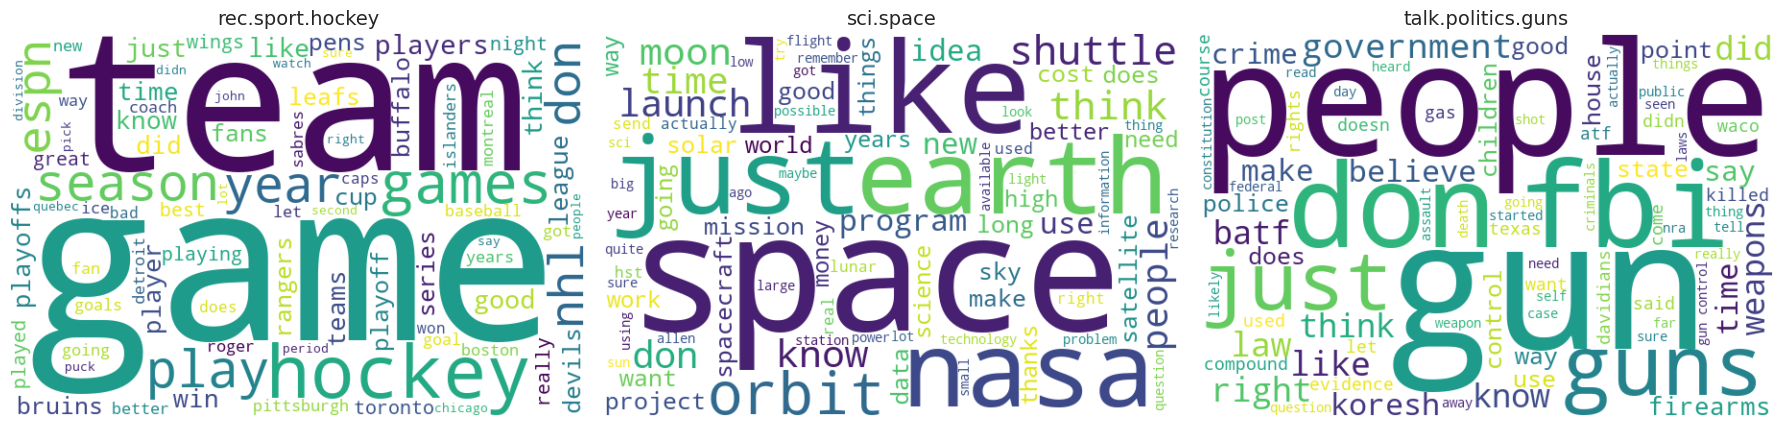

In [26]:
from wordcloud import WordCloud

X_txt_tr, X_txt_te, y_txt_tr, y_txt_te = train_test_split(
    df.text, df.label, test_size=0.25, stratify=df.label, random_state=SEED)

vec_cloud = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.5, max_features=30000, sublinear_tf=True)
M = vec_cloud.fit_transform(X_txt_tr)
vocab = np.array(vec_cloud.get_feature_names_out())

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for c, ax in enumerate(axes):
    mean_w = np.asarray(M[(y_txt_tr == c).values].mean(axis=0)).ravel()
    top = mean_w.argsort()[::-1][:80]
    wc = WordCloud(width=600, height=400, background_color="white", colormap="viridis", random_state=SEED)
    wc.generate_from_frequencies({vocab[i]: mean_w[i] for i in top})
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off"); ax.set_title(class_names[c], fontsize=14)
plt.tight_layout(); plt.show()

У результаті побудови хмар слів для трьох тематичних категорій датасету 20 Newsgroups було виявлено характерні слова та словосполучення, які відображають основний зміст документів кожного класу. Для категорії rec.sport.hockey найбільш значущими виявилися слова team, game, hockey, play, season, players, що безпосередньо пов'язані з хокейними матчами, командами та спортивними сезонами. У категорії sci.space переважають слова space, nasa, earth, orbit, shuttle, launch, moon, які характеризують космічні дослідження, польоти та космічні технології. Для категорії talk.politics.guns найважливішими стали people, gun, guns, government, law, weapons, crime, що відображає обговорення зброї, законодавства та суспільно-політичних питань. Розмір слів у хмарах відповідає їхній середній вазі TF-IDF, тобто більш помітні слова мають вищу значущість у документах відповідної категорії. Таким чином, результати показують, що кожна категорія має характерний словниковий склад, який може бути корисним для подальшої автоматичної класифікації текстів.

### 3.3 Векторизація та навчання моделей

У цьому фрагменті коду виконується перетворення текстових даних у числові ознаки за допомогою TF-IDF, навчання та порівняння трьох моделей класифікації текстів. Спочатку за допомогою TfidfVectorizer тексти перетворюються на числову матрицю, яка враховує окремі слова та словосполучення з двох слів, а максимальна кількість ознак обмежується 50 000. При цьому TF-IDF навчається лише на тренувальній вибірці, щоб уникнути витоку інформації з тестових даних. Далі створюються три моделі машинного навчання: Logistic Regression (логістична регресія), LinearSVC (лінійний метод опорних векторів) та Multinomial Naive Bayes (наївний баєсівський класифікатор). Кожна модель навчається на тренувальних даних, після чого виконує прогнозування категорій текстів на тестовій вибірці. Для оцінювання ефективності обчислюються Accuracy (частка правильних прогнозів), F1-macro (середнє значення F1-score для трьох класів) та час навчання. Отримані результати зберігаються в таблиці та сортуються за F1-macro у спадному порядку, що дозволяє визначити найкращу модель для класифікації текстових документів.

In [27]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.5, max_features=50000, sublinear_tf=True)
Xv_tr = tfidf.fit_transform(X_txt_tr)       # fit лише на train
Xv_te = tfidf.transform(X_txt_te)
print("Матриця TF-IDF (train):", Xv_tr.shape)

models = {
    "LogisticRegression": LogisticRegression(max_iter=2000, random_state=SEED),
    "LinearSVC": LinearSVC(random_state=SEED),
    "MultinomialNB": MultinomialNB(alpha=0.1),
}
rows, fitted = [], {}
for name, m in models.items():
    t = time.perf_counter(); m.fit(Xv_tr, y_txt_tr); dt = time.perf_counter() - t
    p = m.predict(Xv_te); fitted[name] = (m, p)
    rows.append(dict(model=name, accuracy=accuracy_score(y_txt_te, p),
                     f1_macro=f1_score(y_txt_te, p, average="macro"), fit_time_s=dt))
results = pd.DataFrame(rows).sort_values("f1_macro", ascending=False)
display(results.round(4))

Матриця TF-IDF (train): (2091, 24487)


,model,accuracy,f1_macro,fit_time_s
2,MultinomialNB,0.9498,0.9496,0.0081
1,LinearSVC,0.9455,0.9454,0.0532
0,LogisticRegression,0.9455,0.9452,1.0209


У результаті перетворення текстових даних за допомогою TF-IDF було сформовано навчальну матрицю з 2091 документа та 24 487 ознак, які представляють слова та словосполучення. Порівняння трьох моделей класифікації показало, що найкращі результати отримав Multinomial Naive Bayes (MultinomialNB) з Accuracy = 0,9498 (94,98%) та F1-macro = 0,9496. Ця модель також виявилася найшвидшою: час навчання становив лише 0,0081 секунди. Модель LinearSVC продемонструвала дещо нижчі показники (Accuracy = 94,55%, F1-macro = 0,9454) із часом навчання 0,0532 секунди. Logistic Regression показала аналогічну точність (94,55%), але навчалася значно довше — 1,0209 секунди. Таким чином, MultinomialNB виявився найефективнішим серед досліджених алгоритмів, оскільки забезпечив найвищу точність класифікації та найменший час навчання. Отримані результати підтверджують ефективність TF-IDF для представлення текстових даних і використання наївного баєсівського класифікатора для їхньої тематичної класифікації.

### 3.4 Оцінка якості найкращої моделі

У цьому фрагменті коду виконується детальне оцінювання найкращої моделі класифікації текстів, яка автоматично обирається за найвищим значенням F1-macro. За попередніми результатами найкращою моделлю є Multinomial Naive Bayes (MultinomialNB). Спочатку за допомогою classification_report() виводиться звіт із метриками Precision (точність позитивних передбачень), Recall (повнота виявлення об'єктів класу), F1-score (гармонійне середнє Precision та Recall) і Support (кількість тестових записів кожного класу). Далі будується матриця помилок (Confusion Matrix), яка показує кількість правильних і неправильних прогнозів для кожної з трьох категорій: хокей, космос та політика і зброя. Значення на головній діагоналі відповідають правильно класифікованим документам, а поза нею — помилкам класифікації. Це дозволяє визначити, які категорії модель розпізнає найкраще, а які найчастіше плутає між собою.

Найкраща модель: MultinomialNB 

                    precision    recall  f1-score   support

  rec.sport.hockey      0.979     0.946     0.962       241
         sci.space      0.938     0.954     0.946       237
talk.politics.guns      0.933     0.950     0.941       219

          accuracy                          0.950       697
         macro avg      0.950     0.950     0.950       697
      weighted avg      0.950     0.950     0.950       697



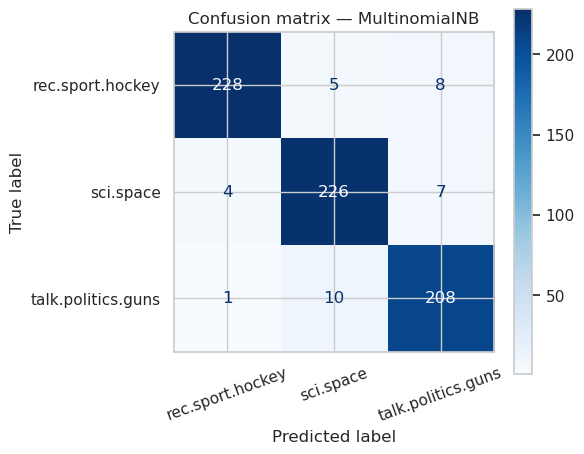

In [28]:
best_name = results.iloc[0].model
best_model, best_pred = fitted[best_name]
print("Найкраща модель:", best_name, "\n")
print(classification_report(y_txt_te, best_pred, target_names=class_names, digits=3))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_txt_te, best_pred, display_labels=class_names, cmap="Blues", ax=ax, xticks_rotation=20)
ax.set_title(f"Confusion matrix — {best_name}"); plt.tight_layout(); plt.show()

За результатами оцінювання найкращою моделлю класифікації текстів виявилася Multinomial Naive Bayes (MultinomialNB), яка досягла Accuracy = 0,950 (95%) та F1-macro = 0,950 на тестовій вибірці з 697 документів. Найкраще модель розпізнає категорію rec.sport.hockey (хокей), для якої F1-score становить 0,962, Precision = 0,979 та Recall = 0,946. Для категорії sci.space (космос) F1-score дорівнює 0,946, а для talk.politics.guns (політика і зброя) — 0,941, що є найнижчим показником серед трьох класів. Аналіз матриці помилок (Confusion Matrix) показав, що модель правильно класифікувала 228 документів про хокей, 226 про космос і 208 про політику та зброю. Загалом із 697 тестових документів 662 класифіковано правильно, а 35 — помилково. Найчастіше модель плутала категорію політики та зброї з космосом (10 випадків), а також хокей із політикою та зброєю (8 випадків). Таким чином, MultinomialNB продемонструвала високу ефективність у тематичній класифікації текстів, забезпечивши збалансовані показники для всіх трьох класів і відносно невелику кількість помилок.

У цьому фрагменті коду виконується аналіз найважливіших слів для кожної категорії та перевірка роботи моделі на нових текстах. Спочатку з навченої моделі логістичної регресії (LogisticRegression) отримуються коефіцієнти, які показують вплив окремих слів і словосполучень на визначення класу. Для кожної з трьох категорій (rec.sport.hockey, sci.space, talk.politics.guns) виводяться 12 ознак із найбільшими додатними коефіцієнтами, тобто найбільш характерних для відповідного класу. Далі створюються три нові речення на теми космосу, хокею та законодавства щодо зброї, які не використовувалися під час навчання. Ці речення проходять попередню обробку за допомогою preprocess(), перетворюються на числові ознаки через навчений TF-IDF векторизатор і передаються найкращій моделі MultinomialNB для прогнозування категорій. Наприкінці виводяться передбачені класи разом із початковими реченнями. Це дозволяє перевірити здатність моделі класифікувати нові тексти та оцінити, які слова найбільше впливають на розпізнавання тематики.

In [29]:
lr = fitted["LogisticRegression"][0]
feat = np.array(tfidf.get_feature_names_out())
for c, cname in enumerate(class_names):
    print(f"{cname:22s}:", ", ".join(feat[lr.coef_[c].argsort()[::-1][:12]]))

samples = ["The shuttle launch to the space station was delayed because of engine problems",
           "The goalie made 30 saves and the team won the game in overtime",
           "Congress is debating new laws about gun ownership and the second amendment"]
pred = best_model.predict(tfidf.transform([preprocess(s) for s in samples]))
for s, p in zip(samples, pred): print(f"{class_names[p]:22s} <- {s}")

rec.sport.hockey      : game, hockey, team, games, nhl, season, play, players, espn, roger, player, cup
sci.space             : space, earth, orbit, nasa, shuttle, moon, launch, sky, solar, program, project, spacecraft
talk.politics.guns    : gun, fbi, guns, weapons, batf, people, government, law, koresh, firearms, house, police
sci.space              <- The shuttle launch to the space station was delayed because of engine problems
rec.sport.hockey       <- The goalie made 30 saves and the team won the game in overtime
talk.politics.guns     <- Congress is debating new laws about gun ownership and the second amendment


За результатами аналізу моделі логістичної регресії було визначено найбільш характерні слова для кожної тематичної категорії. Для rec.sport.hockey (хокей) найважливішими виявилися game, hockey, team, nhl, season, players, для sci.space (космос) — space, earth, orbit, nasa, shuttle, moon, а для talk.politics.guns (політика і зброя) — gun, fbi, guns, weapons, government, law. Ці слова відповідають тематиці своїх категорій, що свідчить про здатність моделі визначати змістовні ознаки текстів. Під час перевірки найкращої моделі MultinomialNB на трьох нових реченнях усі прогнози виявилися правильними: повідомлення про запуск космічного шатла було віднесено до категорії космосу, про хокейний матч — до хокею, а про законодавство щодо зброї — до політики та зброї. Таким чином, результати демонструють, що моделі успішно виділяють тематичні особливості текстів, а MultinomialNB здатна правильно класифікувати нові повідомлення, які не використовувалися під час навчання.

### 3.5 Висновки

У ході практичної роботи було досліджено методи зменшення розмірності даних PCA та t-SNE, алгоритм кластеризації K-Means і методи класифікації текстів. Застосування PCA дозволило скоротити кількість ознак із 30 до 18 (на 40%) зі збереженням 95% дисперсії, при цьому точність класифікації залишилася на рівні 100%, а час навчання зменшився майже вдвічі. Методи PCA та t-SNE забезпечили чітку візуалізацію класів у двовимірному просторі. Для K-Means найкращі результати отримано при k = 3 (ARI = 0,515, NMI = 0,706), однак низький Silhouette Score = 0,138 свідчить про слабку відокремленість кластерів. Також було встановлено, що кластери не завжди відповідають справжнім класам даних.

Під час класифікації текстів датасету 20 Newsgroups було виконано очищення документів, перетворення текстів у числові ознаки за допомогою TF-IDF та порівняння трьох моделей: Logistic Regression, LinearSVC і MultinomialNB. Найкращі результати показала MultinomialNB з Accuracy = 94,98% та F1-macro = 0,9496, правильно класифікувавши 662 із 697 тестових документів. Перевірка на нових реченнях також підтвердила здатність моделі розпізнавати тематику текстів. Таким чином, у роботі було продемонстровано ефективність досліджених алгоритмів для аналізу, візуалізації, кластеризації та класифікації даних, а також важливість правильного вибору методів залежно від поставленого завдання.